In [80]:
import nltk
nltk.download('all')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to /root/nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to /root/nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_ru is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_r

True

In [81]:
import pandas as pd
import numpy as np
import re
import warnings
warnings.filterwarnings('ignore')
import spacy
nlp= spacy.load('en_core_web_sm')
import wordcloud
import string
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize,word_tokenize
from nltk.stem.porter import PorterStemmer
from nltk.stem import WordNetLemmatizer

In [82]:
### Stopwords
stop = stopwords.words('english')
print(stop)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [83]:
len(stop)

198

In [84]:
## Punctuations
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [85]:
## Lemmatization # Mannual Aprroach
lemma = WordNetLemmatizer()
lemma.lemmatize('running',pos='v')

'run'

* If our word part speach is verb = 'v' if
noun = 'n' & if adjective = 'a' & if its adverb = 'r'.

In [86]:
lemma.lemmatize('better',pos='a')

'good'

In [87]:
### Stemming
stem = PorterStemmer()
stem.stem('running')

'run'

* Stemming reomves the last few letters of the word.
* The word may be whatever it always removes last few letters.

In [88]:
stem.stem('beautiful')

'beauti'

In [89]:
### Tokenization
sent = 'Data science class started on may 2026. The classes are going well so far'

In [90]:
words = word_tokenize(sent)
words

['Data',
 'science',
 'class',
 'started',
 'on',
 'may',
 '2026',
 '.',
 'The',
 'classes',
 'are',
 'going',
 'well',
 'so',
 'far']

In [91]:
sentence = sent_tokenize(sent)
print(sentence)

['Data science class started on may 2026.', 'The classes are going well so far']


* There are two types of tokenizers
* 1. Word tokenizer:- it separte the words comas evrything in the sentence it separtes them.
* 2. Sentnce tokenizer = it seprates the senctence when it getes the full stop in the sentences.

In [92]:
doc = nlp(sent)
doc

Data science class started on may 2026. The classes are going well so far

In [93]:
nlp.vocab['may'].is_stop=False

In [94]:
for token in doc:
  print(token.text,token.pos,spacy.explain(token.pos_),token.lemma_,
        token.is_stop,token.is_punct,token.is_digit,token.is_currency)

Data 92 noun data False False False False
science 92 noun science False False False False
class 92 noun class False False False False
started 100 verb start False False False False
on 85 adposition on True False False False
may 96 proper noun may False False False False
2026 93 numeral 2026 False False True False
. 97 punctuation . False True False False
The 90 determiner the True False False False
classes 92 noun class False False False False
are 87 auxiliary be True False False False
going 100 verb go False False False False
well 86 adverb well True False False False
so 86 adverb so True False False False
far 86 adverb far False False False False


* The spacy function will give us lot of info about the words is word belong to which speech if there is any currency in our sentence yes means it give true no means for that word gives false. like there are many info "Spacy" provieds information about the word.

### Named Entity Recognition


In [95]:
sent

'Data science class started on may 2026. The classes are going well so far'

In [96]:
for token in doc.ents:
  print(token.text,token.label_,spacy.explain(token.label_),
        token.start_char,token.end_char)

may 2026 DATE Absolute or relative dates or periods 30 38


* The NLP read the text data and based on its understanding it's assign the 'tag' known as 'Entity'.
* For Eg... If text data is belonging to particular person firictional charater for them its assign the "label tag as Person".
*  If it's speaking about nationality or political group its assigns as NORP. If talking about time its asign as Date.

In [97]:
spacy.displacy.render(doc,style='ent')

### WordCloud

In [98]:
course = 'DataScience, DataAnalyst,AI,Python, DataEngineer,Python,DataScience,Tableau, PowerBI'

In [99]:
from wordcloud import WordCloud, STOPWORDS
import matplotlib.pyplot as plt

In [100]:
## If we do not wants certain
## words we can use the this code make them stop words
stop = STOPWORDS.update(['Tableau','PowerBI'])

In [101]:
word_c = WordCloud(width=1000,height=1000,background_color='white',stopwords=stop).generate(course)
word_c

In [102]:
def word_cloud(data):
  plt.figure(figsize=(10,10))
  plt.imshow(word_c)
  plt.axis('off')
  plt.savefig('word_clpud.jpeg')

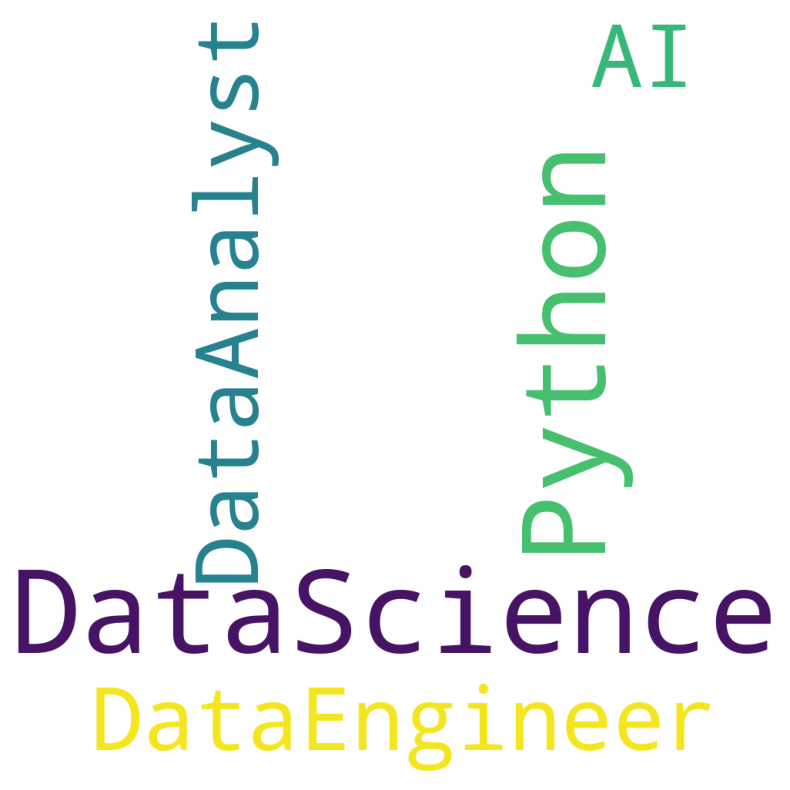

In [103]:
word_cloud(word_c)

* The word cloud analyze the document and it will pick important words and display it.
* The word cloud by default will not pick the stop word.
* So it idenfity the word and which word is repeating more with the bigger fornt size it display it.

In [104]:
 corpus = ['This is the data science class with SL',
           'AI is the next class',
           'and this is third class',
           'and this is fourth class']

In [105]:
from sklearn.feature_extraction.text import CountVectorizer,TfidfTransformer,TfidfVectorizer

In [113]:
## CountVetctorizer
count = CountVectorizer(ngram_range=(1,1),max_features=6)
x = count.fit_transform(corpus).toarray()
x

array([[0, 1, 0, 1, 1, 1],
       [0, 1, 0, 1, 1, 0],
       [1, 1, 0, 1, 0, 1],
       [1, 1, 1, 1, 0, 1]])

* The max features function will only take and make the count vectorizer for word repeating more in the document.

In [114]:
## This will give order of the words for vectorization.
print(count.get_feature_names_out())

['and' 'class' 'fourth' 'is' 'the' 'this']


In [115]:
count.vocabulary_.items()

dict_items([('this', np.int64(5)), ('is', np.int64(3)), ('the', np.int64(4)), ('class', np.int64(1)), ('and', np.int64(0)), ('fourth', np.int64(2))])

In [116]:
## TfidfTransformer
tfidf = TfidfTransformer()
x_tfidf = tfidf.fit_transform(x).toarray()
x_tfidf

array([[0.        , 0.41599288, 0.        , 0.41599288, 0.6284927 ,
        0.50881901],
       [0.        , 0.48322183, 0.        , 0.48322183, 0.73006392,
        0.        ],
       [0.6284927 , 0.41599288, 0.        , 0.41599288, 0.        ,
        0.50881901],
       [0.49144966, 0.32528549, 0.62334157, 0.32528549, 0.        ,
        0.39787085]])

In [118]:
### TfidfVectorizer
tfidf_vect = TfidfVectorizer(ngram_range=(1,1))
x_tfidf_vect = tfidf_vect.fit_transform(corpus).toarray()
x_tfidf_vect

array([[0.        , 0.        , 0.22103912, 0.42357521, 0.        ,
        0.22103912, 0.        , 0.42357521, 0.42357521, 0.33395156,
        0.        , 0.27036257, 0.42357521],
       [0.56199026, 0.        , 0.29326983, 0.        , 0.        ,
        0.29326983, 0.56199026, 0.        , 0.        , 0.44307958,
        0.        , 0.        , 0.        ],
       [0.        , 0.49144966, 0.32528549, 0.        , 0.        ,
        0.32528549, 0.        , 0.        , 0.        , 0.        ,
        0.62334157, 0.39787085, 0.        ],
       [0.        , 0.49144966, 0.32528549, 0.        , 0.62334157,
        0.32528549, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.39787085, 0.        ]])

## Data Cleaning

In [124]:
data = 'Data Science class *)(())))**($#^!$$<>)) strated'
' '.join(re.findall('\w+',data))

'Data Science class strated'

* The small w will reomve the characters.
* Join function used to get the word is sentence format.

In [131]:
### Data Cleaning
def data_clean(data):
  text = ' '.join(re.findall('\w+',data))
  doc = nlp(text)
  cleaned_data = [token.lemma_ for token in doc if not token.is_stop
                  and not token.is_punct and not token.is_digit
                  and not token.is_bracket and not token.is_currency]
  return cleaned_data

In [135]:
data_clean('Data Science class is going well and strated in the year of 20209$#$%()$%(#+$)')

['Data', 'Science', 'class', 'go', 'strate', 'year']

* The above code will first filter the non-alph numerics(re.findall('\w+',data). and save in the text varible to text variable the spacy packge is applied.
* Next it will apply lemmatixation and cross validate each input if the input is not stop word digigt bracket and currency like that it cross validate all the function and if its staisfy all conditions those inputs will be printed.

In [136]:
count = CountVectorizer(ngram_range=(1,1),analyzer=data_clean)
x = count.fit_transform(corpus).toarray()
x

array([[0, 1, 1, 1, 0, 1],
       [1, 0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0, 0],
       [0, 0, 1, 0, 1, 0]])

* So we can use the above created function here by passing it under analyzer it will first pass the input to this function and it will do the further process.

In [137]:
print(count.get_feature_names_out())

['AI' 'SL' 'class' 'data' 'fourth' 'science']


In [139]:
## TfidfVectiorizer
tfidf_vect = TfidfVectorizer(ngram_range=(1,1),max_features=13,analyzer=data_clean)
x_tfidd = tfidf_vect.fit_transform(corpus).toarray()
x_tfidd

array([[0.        , 0.55280532, 0.28847675, 0.55280532, 0.        ,
        0.55280532],
       [0.88654763, 0.        , 0.46263733, 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 1.        , 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.46263733, 0.        , 0.88654763,
        0.        ]])